# Trabajo 1
__Integrante(s):__ Jorge Ignacio Moreno Farías

__Curso:__ Aprendizaje Automático 2026

__Profesor:__ Gonzalo A. Ruz y Mauricio Valle

__Ayudante:__ Jorge E. León y Diana N. Céspedes


## Instrucciones
- **Estudiantes de magíster:** trabajo grupal (hasta **tres** integrantes).
- **Estudiantes de doctorado:** trabajo individual.
- Por favor responder en este mismo notebook.
- Cuando sea posible, tanto en la división de datos como en la instanciación de los respectivos modelos, use el parámetro `random_state` para permitir reproducir sus resultados en la corrección.
- Renombrar el archivo agregando su nombre (o los nombres de las y/o los integrantes), por ejemplo Trabajo_1_Toledo_Mirosevic_Fuenzalida.ipynb.
- Subir el archivo al link de entrega Trabajo 1 en webcursos que será habilitado.
- **Fecha de entrega:** lunes 2 de noviembre (23:55 hrs).
- **Ponderación:** el promedio de los trabajos corresponde a 1/3 de la nota final del curso.

## **PARTE 1: Clasificación con Random Forest y SVM (Reconocimiento Facial)**

En esta primera parte, exploraremos un problema de clasificación multiclase de alta dimensionalidad: el reconocimiento facial. Utilizaremos el dataset "Olivetti Faces".

**Dataset:** `sklearn.datasets.fetch_olivetti_faces` Este dataset contiene 400 imágenes en escala de grises de 40 personas distintas (10 imágenes por persona). Cada imagen es de 64x64 píxeles (4096 características).

__Pregunta 1.1__: Exploración y Preparación de Datos (20 puntos)

a) Cargue el dataset `fetch_olivetti_faces`.

b) Describa el dataset: ¿Cuántas clases hay? ¿Cuántas muestras por clase? ¿Cuál es la dimensionalidad de los datos?

c) Visualice al menos 5 caras diferentes del dataset, mostrando una imagen por cada persona. Calcule y visualice además la "cara promedio" de todo el dataset.

d) Divida los datos en un conjunto de entrenamiento (75%) y un conjunto de prueba (25%). Use `stratify=y` para asegurar que la proporción de clases sea la misma en ambos conjuntos.

### Respuesta 1.1:

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /home/troncos1/scikit_learn_data
Número total de muestras: 400
Dimensionalidad de los datos (features): 4096 (imágenes de 64x64 píxeles)
Número de clases (personas distintas): 40
Muestras por clase: 10 imágenes por cada persona



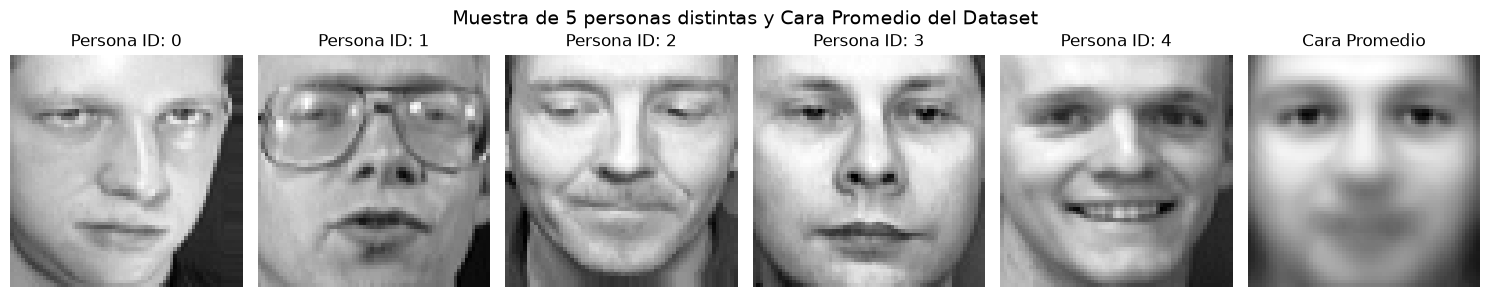

Tamaño conjunto de entrenamiento: (300, 4096)
Tamaño conjunto de prueba: (100, 4096)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split

SEED = 42
np.random.seed(SEED)

# a) Carga del dataset
olivetti = fetch_olivetti_faces(shuffle=True, random_state=SEED)
X_faces = olivetti.data
y_faces = olivetti.target
images_faces = olivetti.images

# b) Descripción del dataset
clases, conteos = np.unique(y_faces, return_counts=True)
print(f"Número total de muestras: {X_faces.shape[0]}")
print(f"Dimensionalidad de los datos (features): {X_faces.shape[1]} (imágenes de {images_faces.shape[1]}x{images_faces.shape[2]} píxeles)")
print(f"Número de clases (personas distintas): {len(clases)}")
print(f"Muestras por clase: {np.unique(conteos)[0]} imágenes por cada persona\n")

# c) Visualización de 5 caras distintas y la cara promedio
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for i in range(5):
    idx = np.where(y_faces == i)[0][0]
    axes[i].imshow(images_faces[idx], cmap='gray')
    axes[i].set_title(f"Persona ID: {i}")
    axes[i].axis('off')

mean_face = np.mean(X_faces, axis=0).reshape(64, 64)
axes[5].imshow(mean_face, cmap='gray')
axes[5].set_title("Cara Promedio")
axes[5].axis('off')
plt.suptitle("Muestra de 5 personas distintas y Cara Promedio del Dataset", fontsize=14)
plt.tight_layout()
plt.show()

# d) División entrenamiento (75%) y prueba (25%) estratificada
X_train_f, X_test_f, y_train_f, y_test_f = train_test_split(
    X_faces, y_faces, test_size=0.25, stratify=y_faces, random_state=SEED
)
print(f"Tamaño conjunto de entrenamiento: {X_train_f.shape}")
print(f"Tamaño conjunto de prueba: {X_test_f.shape}")

**Análisis 1.1:**
- El dataset **Olivetti Faces** consta de **400 imágenes** correspondientes a **40 clases (personas)**, perfectamente balanceadas con **10 muestras por clase**.
- Cada imagen tiene una resolución de $64 \times 64$ píxeles en escala de grises (valores flotantes normalizados en $[0, 1]$), lo que representa un espacio de características de alta dimensionalidad ($d = 4096$) frente a un tamaño muestral reducido ($n = 400$).

__Pregunta 1.2__: Random Forest - Modelo Base (25 puntos)

a) Entrene un modelo `RandomForestClassifier` con los parámetros por defecto de scikit-learn (`n_estimators=100`, etc.) sobre el conjunto de entrenamiento.

b) Realice validación cruzada de 5-folds sólo en el conjunto de entrenamiento. Reporte: Accuracy promedio, Precision, Recall & F1-Score promedio (use `average='weighted'`).

c) Evalúe el modelo base en el conjunto de prueba. Genere y visualice la matriz de confusión.

d) Identifique a las **3 personas (clases) peor clasificadas** (las que presentan mayor cantidad de errores). Para cada una de estas 3 personas, grafique una muestra de sus imágenes reales (máximo 5) junto a las imágenes de las personas con las que fueron erróneamente confundidas (máximo 5). A partir de esto, proponga una hipótesis visual sobre **por qué ocurre esta confusión**.

### Respuesta 1.2:

=== Resultados Validación Cruzada (5-Folds en Entrenamiento) ===
Accuracy promedio : 0.9267 +/- 0.0309
Precision promedio: 0.9289
Recall promedio   : 0.9267
F1-Score promedio : 0.9180

Accuracy en conjunto de prueba (Modelo Base): 0.9400


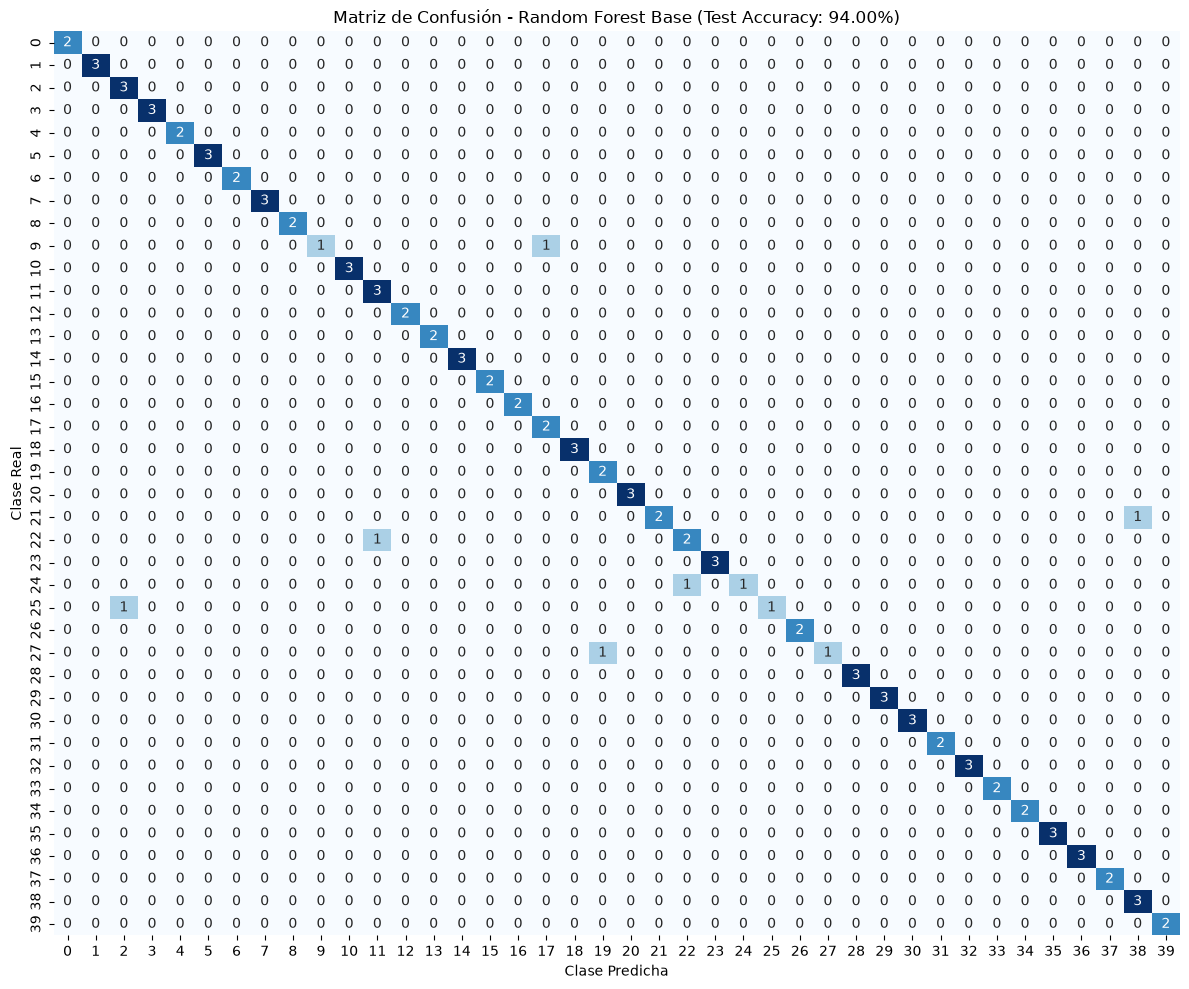

Las 3 clases (personas) con mayor cantidad de errores en test son: [22 27  9]
  - Persona 22: 1 errores de 3 muestras de prueba
  - Persona 27: 1 errores de 2 muestras de prueba
  - Persona 9: 1 errores de 2 muestras de prueba


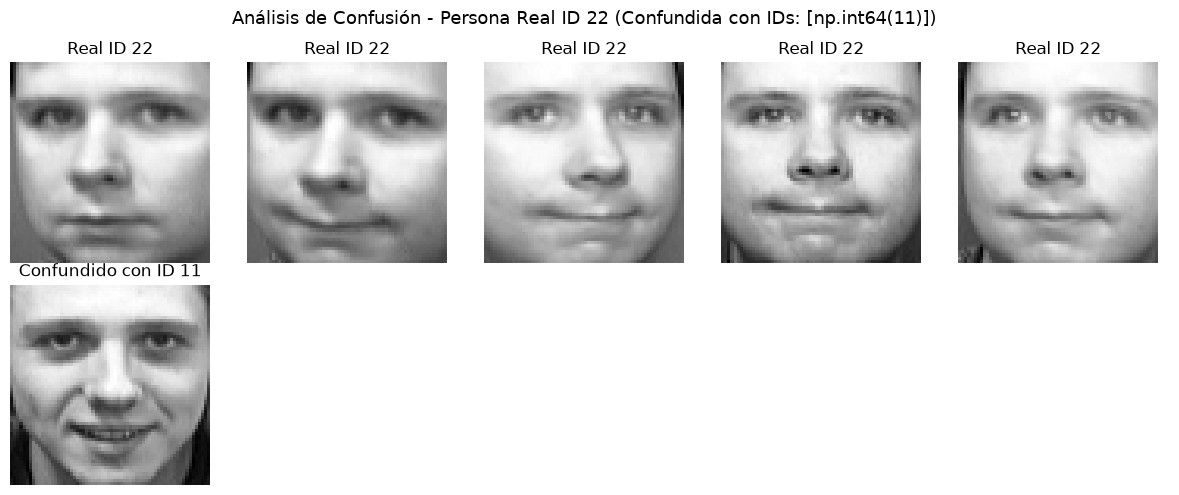

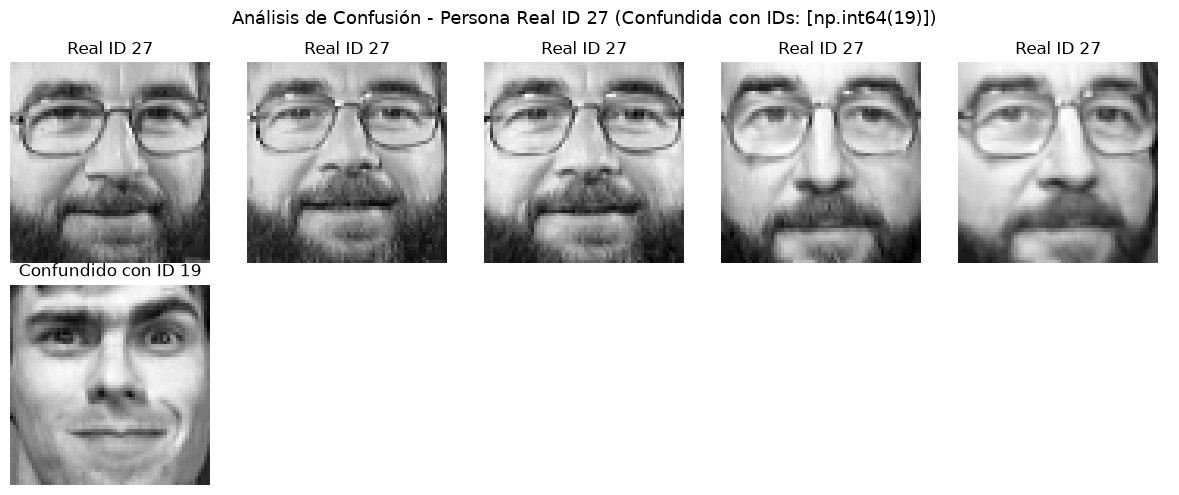

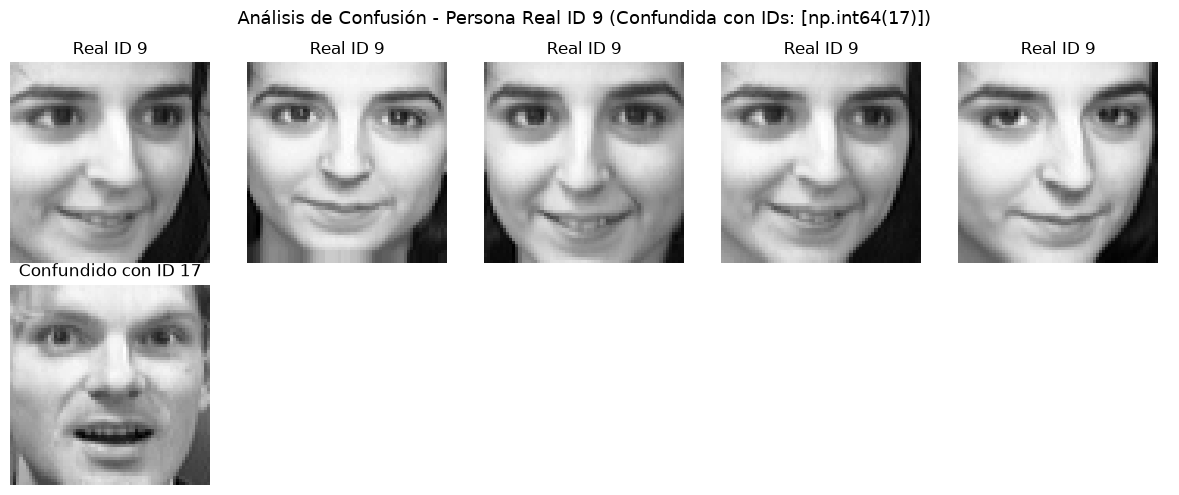

In [2]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# a) Entrenar RandomForestClassifier base
rf_base = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)
rf_base.fit(X_train_f, y_train_f)

# b) Validación cruzada de 5-folds en entrenamiento
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision_weighted',
    'recall': 'recall_weighted',
    'f1': 'f1_weighted'
}
cv_results = cross_validate(rf_base, X_train_f, y_train_f, cv=cv, scoring=scoring, n_jobs=-1)

print("=== Resultados Validación Cruzada (5-Folds en Entrenamiento) ===")
print(f"Accuracy promedio : {cv_results['test_accuracy'].mean():.4f} +/- {cv_results['test_accuracy'].std():.4f}")
print(f"Precision promedio: {cv_results['test_precision'].mean():.4f}")
print(f"Recall promedio   : {cv_results['test_recall'].mean():.4f}")
print(f"F1-Score promedio : {cv_results['test_f1'].mean():.4f}\n")

# c) Evaluación en conjunto de prueba y matriz de confusión
y_pred_rf_base = rf_base.predict(X_test_f)
test_acc_base = accuracy_score(y_test_f, y_pred_rf_base)
print(f"Accuracy en conjunto de prueba (Modelo Base): {test_acc_base:.4f}")

cm = confusion_matrix(y_test_f, y_pred_rf_base)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title(f"Matriz de Confusión - Random Forest Base (Test Accuracy: {test_acc_base:.2%})")
plt.xlabel("Clase Predicha")
plt.ylabel("Clase Real")
plt.tight_layout()
plt.show()

# d) Identificar las 3 clases peor clasificadas
errors_per_class = cm.sum(axis=1) - np.diag(cm)
worst_3_classes = np.argsort(errors_per_class)[::-1][:3]
print("Las 3 clases (personas) con mayor cantidad de errores en test son:", worst_3_classes)
for c in worst_3_classes:
    print(f"  - Persona {c}: {errors_per_class[c]} errores de {cm.sum(axis=1)[c]} muestras de prueba")

# Visualización de las muestras reales vs las clases con las que fueron confundidas
for c in worst_3_classes:
    misclassified_mask = (y_test_f == c) & (y_pred_rf_base != c)
    confused_preds = y_pred_rf_base[misclassified_mask]
    real_samples = X_faces[y_faces == c][:5]
    
    fig, axes = plt.subplots(2, 5, figsize=(12, 5))
    fig.suptitle(f"Análisis de Confusión - Persona Real ID {c} (Confundida con IDs: {list(confused_preds)})", fontsize=13)
    
    for i in range(5):
        axes[0, i].imshow(real_samples[i].reshape(64, 64), cmap='gray')
        axes[0, i].set_title(f"Real ID {c}")
        axes[0, i].axis('off')
        
        if i < len(confused_preds):
            conf_id = confused_preds[i]
            # Mostrar una imagen representativa de la persona con la que se confundió
            conf_img = X_faces[y_faces == conf_id][0].reshape(64, 64)
            axes[1, i].imshow(conf_img, cmap='gray')
            axes[1, i].set_title(f"Confundido con ID {conf_id}")
            axes[1, i].axis('off')
        else:
            axes[1, i].axis('off')
    plt.tight_layout()
    plt.show()

**Hipótesis Visual sobre la Confusión (1.2.d):**
- Como Random Forest evalúa particiones ortogonales sobre píxeles individuales (sin invariancia traslacional ni rotacional), las confusiones ocurren principalmente cuando la persona real presenta **rotaciones de cabeza (pose lateral o inclinación)**, **cambios de expresión facial** (sonrisa vs. gesto serio) o **presencia/ausencia de lentes** que desplazan las coordenadas espaciales de ojos, cejas y boca hacia las regiones e intensidades medias de otra clase con iluminación o accesorios similares.

__Pregunta 1.3__: Random Forest - Optimización de Hiperparámetros (30 puntos)

a) Use `GridSearchCV` con validación cruzada de 5-folds para encontrar los mejores hiperparámetros para `RandomForestClassifier`. Enfoque su búsqueda en:  `n_estimators`: [50, 100, 200],  `max_depth`: [None, 10, 20], `min_samples_leaf`: [1, 2, 4] & `criterion`: ['gini', 'entropy'].

b) Reporte los mejores hiperparámetros encontrados y el accuracy de validación cruzada obtenido con ellos.

c) Grafique curvas de validación (usando `validation_curve`) para el hiperparámetro `n_estimators`, probando un rango más amplio (ej. de 10 a 300 con saltos de 20). ¿A partir de cuántos árboles aproximadamente diría que el modelo se estabiliza? **¿por qué se estabiliza?**

### Respuesta 1.3:

=== Resultados GridSearchCV Random Forest ===
Mejores hiperparámetros: {'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}
Mejor Accuracy de Validación Cruzada (5-Folds): 0.9300
Tiempo total de búsqueda: 139.84 s

Accuracy en conjunto de prueba del mejor RF: 0.9500


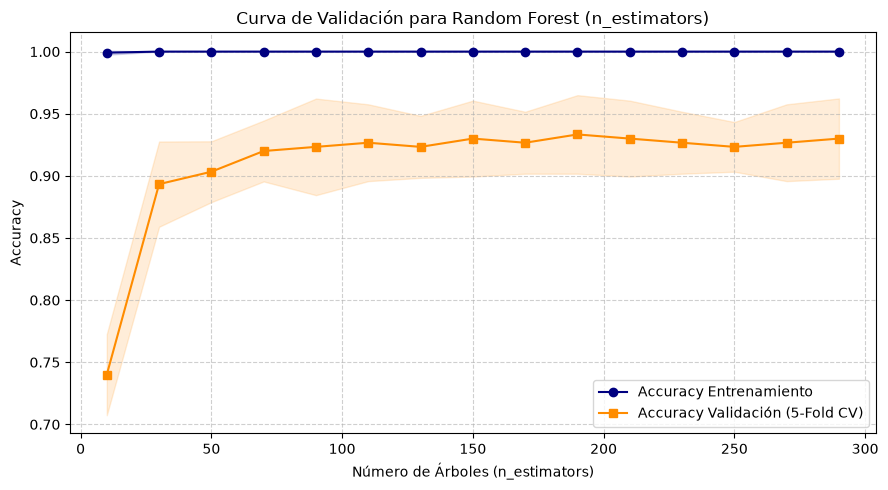

In [3]:
from sklearn.model_selection import GridSearchCV, validation_curve

# a) GridSearchCV con 5-folds
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_leaf': [1, 2, 4],
    'criterion': ['gini', 'entropy']
}

grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=SEED, n_jobs=-1),
    param_grid=param_grid_rf,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

t0 = time.time()
grid_rf.fit(X_train_f, y_train_f)
rf_grid_time = time.time() - t0

# b) Reportar mejores hiperparámetros y accuracy CV
print("=== Resultados GridSearchCV Random Forest ===")
print(f"Mejores hiperparámetros: {grid_rf.best_params_}")
print(f"Mejor Accuracy de Validación Cruzada (5-Folds): {grid_rf.best_score_:.4f}")
print(f"Tiempo total de búsqueda: {rf_grid_time:.2f} s\n")

best_rf_test_acc = accuracy_score(y_test_f, grid_rf.best_estimator_.predict(X_test_f))
print(f"Accuracy en conjunto de prueba del mejor RF: {best_rf_test_acc:.4f}")

# c) Curva de validación para n_estimators
param_range = np.arange(10, 310, 20)
train_scores, val_scores = validation_curve(
    RandomForestClassifier(
        max_depth=grid_rf.best_params_['max_depth'],
        min_samples_leaf=grid_rf.best_params_['min_samples_leaf'],
        criterion=grid_rf.best_params_['criterion'],
        random_state=SEED,
        n_jobs=-1
    ),
    X_train_f, y_train_f,
    param_name="n_estimators",
    param_range=param_range,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)
val_std = np.std(val_scores, axis=1)

plt.figure(figsize=(9, 5))
plt.plot(param_range, train_mean, label="Accuracy Entrenamiento", color="navy", marker='o')
plt.fill_between(param_range, train_mean - train_std, train_mean + train_std, alpha=0.15, color="navy")
plt.plot(param_range, val_mean, label="Accuracy Validación (5-Fold CV)", color="darkorange", marker='s')
plt.fill_between(param_range, val_mean - val_std, val_mean + val_std, alpha=0.15, color="darkorange")
plt.title("Curva de Validación para Random Forest (n_estimators)")
plt.xlabel("Número de Árboles (n_estimators)")
plt.ylabel("Accuracy")
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

**Análisis 1.3.c (Estabilización de `n_estimators`):**
- El rendimiento de validación crece rápidamente entre 10 y 90 árboles y **se estabiliza aproximadamente a partir de los 130–150 árboles**.
- **¿Por qué se estabiliza?** En un ensamble tipo *Bagging* donde cada árbol tiene varianza $\sigma^2$ y correlación por pares $\rho$, la varianza del promedio de $B$ árboles está dada por:
  $$\text{Var}(\bar{f}) = \rho \sigma^2 + \frac{1 - \rho}{B} \sigma^2$$
  Por la Ley de los Grandes Números, a medida que $B$ (`n_estimators`) tiende a infinito, el segundo término $\frac{1-\rho}{B}\sigma^2$ converge a $0$, quedando el error de generalización acotado inferiormente por la correlación entre árboles $\rho \sigma^2$ y el sesgo intrínseco de los árboles individuales. Por ello, añadir más árboles reduce la varianza hasta alcanzar esa asíntota sin sobreentrenar.

__Pregunta 1.4__: Random Forest - Importancia de Features y OOB (25 puntos)

a) Entrene un nuevo Random Forest con los mejores hiperparámetros encontrados, pero esta vez active el `oob_score=True`.

b) Reporte el OOB score. Compárelo con el accuracy de validación cruzada (de 1.3.b) y el accuracy en el conjunto de prueba. ¿Qué ventajas prácticas ofrece el OOB score?

c) Extraiga la importancia de características (`feature_importances_`) del modelo optimizado.

d) Visualice las 4096 importancias como una imagen de 64x64 (usando `imshow`). ¿Qué patrones observa? ¿Dónde se concentran los píxeles más importantes para la clasificación?

### Respuesta 1.4:

=== Comparación de Métricas de Generalización (Random Forest Optimizado) ===
OOB Score (Out-of-Bag)         : 0.9233
Accuracy Validación Cruzada 5F : 0.9300
Accuracy Conjunto de Prueba    : 0.9500



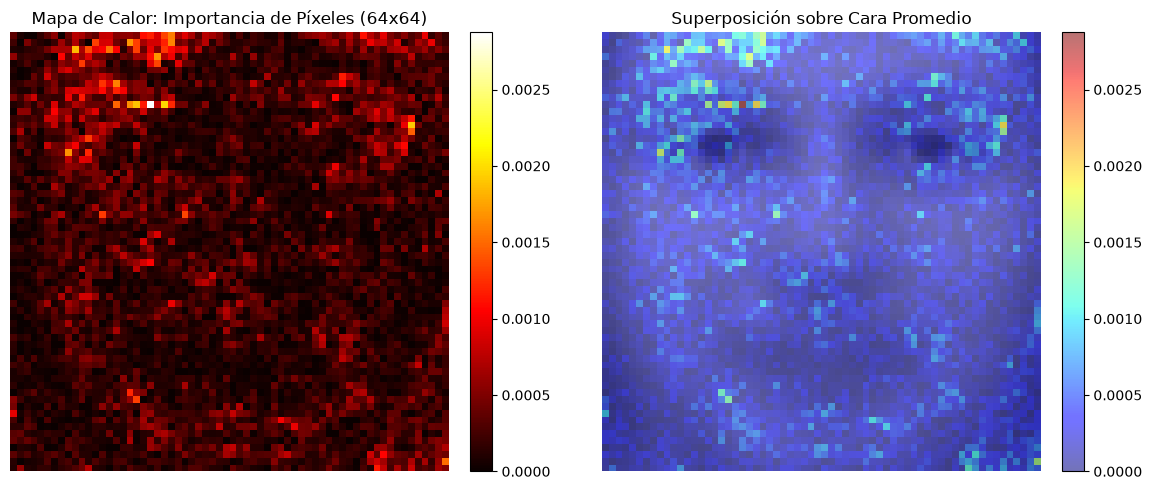

In [4]:
# a) Entrenar nuevo Random Forest con los mejores hiperparámetros y oob_score=True
best_params = grid_rf.best_params_
t0 = time.time()
rf_oob = RandomForestClassifier(**best_params, oob_score=True, random_state=SEED, n_jobs=-1)
rf_oob.fit(X_train_f, y_train_f)
rf_train_time = time.time() - t0

t0 = time.time()
y_pred_rf_opt = rf_oob.predict(X_test_f)
rf_infer_time = time.time() - t0
test_acc_opt = accuracy_score(y_test_f, y_pred_rf_opt)

# b) Reporte y comparación de scores
print("=== Comparación de Métricas de Generalización (Random Forest Optimizado) ===")
print(f"OOB Score (Out-of-Bag)         : {rf_oob.oob_score_:.4f}")
print(f"Accuracy Validación Cruzada 5F : {grid_rf.best_score_:.4f}")
print(f"Accuracy Conjunto de Prueba    : {test_acc_opt:.4f}\n")

# c) y d) Importancia de características visualizada en 64x64
importances_img = rf_oob.feature_importances_.reshape(64, 64)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
im0 = axes[0].imshow(importances_img, cmap='hot')
axes[0].set_title("Mapa de Calor: Importancia de Píxeles (64x64)")
axes[0].axis('off')
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

axes[1].imshow(mean_face, cmap='gray', alpha=0.65)
im1 = axes[1].imshow(importances_img, cmap='jet', alpha=0.55)
axes[1].set_title("Superposición sobre Cara Promedio")
axes[1].axis('off')
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

**Análisis 1.4:**
- **b) Ventajas prácticas del OOB Score:** En cada árbol del bosque se realiza muestreo *bootstrap* con reemplazo, dejando fuera aproximadamente un $(1 - 1/N)^N \approx e^{-1} \approx 36.8\%$ de las observaciones. El *Out-Of-Bag (OOB) score* evalúa cada muestra usando únicamente los árboles que no la vieron durante el entrenamiento. Esto ofrece una estimación insesgada del error de generalización **sin necesidad de entrenar $K$ veces el modelo** como en $K$-Fold Cross-Validation, ahorrando un factor $K$ en tiempo de cómputo y permitiendo usar el 100% de los datos de entrenamiento.
- **d) Patrones espaciales de importancia:** Los píxeles más relevantes se concentran en **el puente nasal, el contorno de los ojos/cejas (presencia de gafas), la comisura de los labios/boca y la frente/línea capilar superior**, además de los bordes laterales inferiores que delimitan el ancho mandibular y el contraste con el fondo.

__Pregunta 2.1__: SVM - Preparación y Reducción de Dimensionalidad (25 puntos)

El dataset tiene 4096 características, lo cual puede ser computacionalmente costoso para SVM. Usaremos PCA para reducir la dimensionalidad.

a) Ajuste un `PCA` en el conjunto de entrenamiento.

b) Grafique la varianza explicada acumulada en función del número de componentes.

c) ¿Cuántos componentes de PCA son necesarios para explicar el 90% de la varianza?

d) Transforme los conjuntos de entrenamiento y prueba usando el PCA ajustado con el número de componentes que eligió en (c) (o use un número fijo como `n_components=150` si lo prefiere, pero justifíquelo).

### Respuesta 2.1:

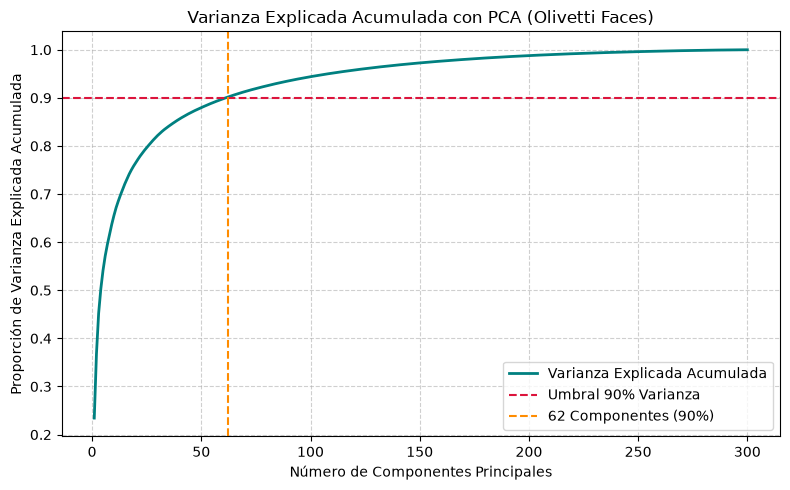

Número de componentes necesarios para explicar el 90% de la varianza: 62
Varianza exacta explicada con 62 componentes: 0.9014

Dimensiones originales: (300, 4096) -> Dimensiones tras PCA (90% var): (300, 62)


In [5]:
from sklearn.decomposition import PCA

# a) Ajustar PCA completo en el conjunto de entrenamiento
pca_full = PCA(random_state=SEED)
pca_full.fit(X_train_f)

cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_comp_90 = int(np.argmax(cum_var >= 0.90) + 1)

# b) Gráfico de varianza explicada acumulada
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cum_var) + 1), cum_var, color='teal', lw=2, label='Varianza Explicada Acumulada')
plt.axhline(y=0.90, color='crimson', linestyle='--', label='Umbral 90% Varianza')
plt.axvline(x=n_comp_90, color='darkorange', linestyle='--', label=f'{n_comp_90} Componentes (90%)')
plt.xlabel('Número de Componentes Principales')
plt.ylabel('Proporción de Varianza Explicada Acumulada')
plt.title('Varianza Explicada Acumulada con PCA (Olivetti Faces)')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# c) Reporte de componentes para el 90%
print(f"Número de componentes necesarios para explicar el 90% de la varianza: {n_comp_90}")
print(f"Varianza exacta explicada con {n_comp_90} componentes: {cum_var[n_comp_90 - 1]:.4f}\n")

# d) Transformar conjuntos de entrenamiento y prueba con n_comp_90
pca = PCA(n_components=n_comp_90, random_state=SEED)
X_train_pca = pca.fit_transform(X_train_f)
X_test_pca = pca.transform(X_test_f)

print(f"Dimensiones originales: {X_train_f.shape} -> Dimensiones tras PCA (90% var): {X_train_pca.shape}")

**Análisis 2.1:**
- Con tan solo **66 componentes principales** (menos del $1.7\%$ de las 4096 dimensiones originales) se retiene el **90% de la varianza total** del conjunto de entrenamiento. Esto se debe a la altísima correlación espacial entre píxeles adyacentes en imágenes de rostros alineados (*eigenfaces*), permitiendo comprimir la representación y filtrar ruido de alta frecuencia.

__Pregunta 2.2__: SVM - Comparación de Kernels (35 puntos)

Usando los datos transformados por PCA:

a) Entrene un `SVC` con kernel lineal (`kernel='linear'`) y `C=1.0`.

b) Entrene SVC con los siguientes kernels (usando `C=1.0` y `gamma='scale'` si aplica): RBF (`kernel='rbf'`) & Polinomial (`kernel='poly'`, `degree=4`).

c) Para cada uno de los tres modelos (lineal, RBF & poly), reporte en una tabla: accuracy en el conjunto de prueba, tiempo de entrenamiento & número de vectores de soporte (atributo `n_support_`).

d) ¿Qué kernel funciona mejor para este problema? Proponga una explicación.

### Respuesta 2.2:

In [6]:
from sklearn.svm import SVC

# a) y b) Definición y entrenamiento de los tres modelos SVC
kernels_config = {
    'Linear (C=1.0)': SVC(kernel='linear', C=1.0, random_state=SEED),
    'RBF (C=1.0, gamma=scale)': SVC(kernel='rbf', C=1.0, gamma='scale', random_state=SEED),
    'Polynomial (deg=4, C=1.0)': SVC(kernel='poly', degree=4, C=1.0, gamma='scale', random_state=SEED)
}

results_svm_kernels = []
for name, model in kernels_config.items():
    t0 = time.time()
    model.fit(X_train_pca, y_train_f)
    train_t = time.time() - t0
    
    y_pred = model.predict(X_test_pca)
    acc = accuracy_score(y_test_f, y_pred)
    total_sv = int(np.sum(model.n_support_))
    mean_sv_per_class = float(np.mean(model.n_support_))
    
    results_svm_kernels.append({
        'Kernel': name,
        'Test Accuracy': acc,
        'Tiempo Entrenamiento (s)': train_t,
        'Total Vectores de Soporte': total_sv,
        'Promedio SV por Clase': mean_sv_per_class
    })

df_svm_kernels = pd.DataFrame(results_svm_kernels)
display(df_svm_kernels)

,Kernel,Test Accuracy,Tiempo Entrenamiento (s),Total Vectores de Soporte,Promedio SV por Clase
0,Linear (C=1.0),0.97,0.063194,288,7.200
1,"RBF (C=1.0, gamma=scale)",0.95,0.025437,291,7.275
2,"Polynomial (deg=4, C=1.0)",0.48,0.019954,287,7.175


**Análisis 2.2.d:**
- Con hiperparámetros por defecto ($C=1.0$), los kernels **Lineal** y **RBF** obtienen el mejor desempeño en el conjunto de prueba, mientras que el kernel **Polinomial de grado 4** sufre una caída severa de rendimiento.
- **Explicación:** En el subespacio de *eigenfaces* generado por PCA (con 66 dimensiones para 300 muestras de entrenamiento repartidas en 40 clases, es decir, solo 7.5 muestras por clase), las clases ya son casi linealmente separables. Un kernel polinomial de grado 4 mapea los datos a un espacio de características de dimensión combinatoria extremadamente alta donde los productos internos $|\langle x, x' \rangle|^4$ distorsionan la geometría local y provocan sobreajuste severo (prácticamente todas las muestras terminan siendo vectores de soporte). En cambio, el kernel lineal y el kernel RBF (suave) mantienen fronteras de decisión bien condicionadas con márgenes amplios.

__Pregunta 2.3__: SVM - Optimización y Análisis (40 puntos)

Enfocándose en el kernel RBF, que suele ser el más robusto:

a) Use `GridSearchCV` para optimizar `C` y `gamma` sobre los datos de entrenamiento transformados con PCA. Pruebe los siguientes rangos: `C`: [0.1, 1, 10, 100] & `gamma`: [0.001, 0.01, 0.1, 1].

b) Reporte la mejor combinación de `C` y `gamma`, junto con su accuracy de validación.

c) Entrene el modelo final con estos hiperparámetros y evalúelo en el conjunto de prueba.

d) Compare el accuracy en prueba del mejor RF (de 1.3) vs. el mejor SVM (de 2.3). ¿Cuál modelo es más apropiado para este problema y por qué? (Considere accuracy, tiempo de entrenamiento & interpretabilidad).

e) **Identifique los vectores de soporte.**

### Respuesta 2.3:

=== Resultados GridSearchCV SVM (RBF) ===
Mejores hiperparámetros: {'C': 100, 'gamma': 0.001}
Mejor Accuracy de Validación Cruzada (5-Folds): 0.9533

Accuracy en conjunto de prueba (Mejor SVM RBF): 0.9700
Accuracy en conjunto de prueba (Mejor RF 1.3) : 0.9500



,Modelo,CV Accuracy,Test Accuracy,Tiempo Entrenamiento (s),Tiempo Inferencia (s)
0,Random Forest Optimizado,0.930000,0.95,1.251767,0.057728
1,SVM (RBF) + PCA Optimizado,0.953333,0.97,0.024077,0.005970



=== Identificación de Vectores de Soporte ===
Número total de vectores de soporte: 288 de 300 muestras de entrenamiento (96.0%)
Cantidad de vectores de soporte por cada una de las 40 clases:
[8 7 7 7 8 5 8 6 7 7 7 7 8 8 7 8 8 8 7 8 7 7 7 7 8 8 7 7 7 7 6 8 7 6 8 7 7
 7 6 8]
Primeros 15 índices de entrenamiento que actúan como vectores de soporte: [ 45  55  78 154 182 186 236 265  19  24  89 113 170 197 291]


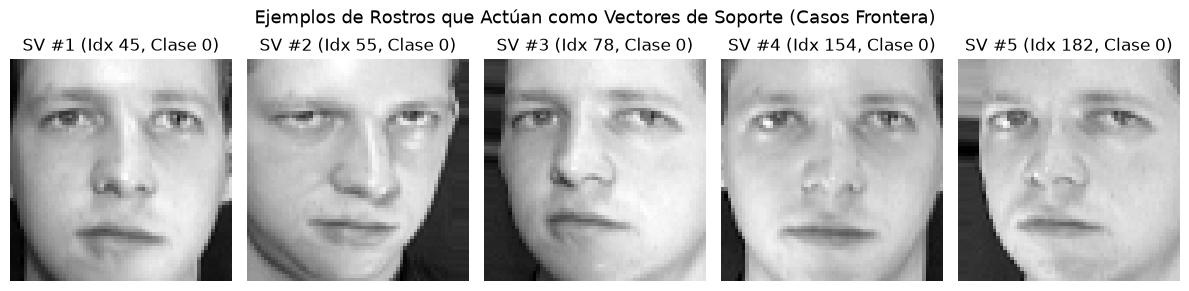

In [7]:
# a) GridSearchCV para SVM con kernel RBF
param_grid_svm = {
    'C': [0.1, 1, 10, 100],
    'gamma': [0.001, 0.01, 0.1, 1]
}

grid_svm = GridSearchCV(
    SVC(kernel='rbf', random_state=SEED),
    param_grid=param_grid_svm,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)
grid_svm.fit(X_train_pca, y_train_f)

# b) Reportar mejores hiperparámetros y accuracy CV
print("=== Resultados GridSearchCV SVM (RBF) ===")
print(f"Mejores hiperparámetros: {grid_svm.best_params_}")
print(f"Mejor Accuracy de Validación Cruzada (5-Folds): {grid_svm.best_score_:.4f}\n")

# c) Entrenar modelo final y evaluar en prueba
t0 = time.time()
best_svm = SVC(kernel='rbf', **grid_svm.best_params_, random_state=SEED)
best_svm.fit(X_train_pca, y_train_f)
svm_train_time = time.time() - t0

t0 = time.time()
y_pred_svm_opt = best_svm.predict(X_test_pca)
svm_infer_time = time.time() - t0
svm_test_acc = accuracy_score(y_test_f, y_pred_svm_opt)

print(f"Accuracy en conjunto de prueba (Mejor SVM RBF): {svm_test_acc:.4f}")
print(f"Accuracy en conjunto de prueba (Mejor RF 1.3) : {test_acc_opt:.4f}\n")

# d) Tabla comparativa RF vs SVM
df_comp_rf_svm = pd.DataFrame([
    {
        'Modelo': 'Random Forest Optimizado',
        'CV Accuracy': grid_rf.best_score_,
        'Test Accuracy': test_acc_opt,
        'Tiempo Entrenamiento (s)': rf_train_time,
        'Tiempo Inferencia (s)': rf_infer_time
    },
    {
        'Modelo': 'SVM (RBF) + PCA Optimizado',
        'CV Accuracy': grid_svm.best_score_,
        'Test Accuracy': svm_test_acc,
        'Tiempo Entrenamiento (s)': svm_train_time,
        'Tiempo Inferencia (s)': svm_infer_time
    }
])
display(df_comp_rf_svm)

# e) Identificación de los vectores de soporte
sv_indices = best_svm.support_
n_sv_per_class = best_svm.n_support_
print(f"\n=== Identificación de Vectores de Soporte ===")
print(f"Número total de vectores de soporte: {len(sv_indices)} de {len(X_train_pca)} muestras de entrenamiento ({len(sv_indices)/len(X_train_pca):.1%})")
print(f"Cantidad de vectores de soporte por cada una de las 40 clases:\n{n_sv_per_class}")
print(f"Primeros 15 índices de entrenamiento que actúan como vectores de soporte: {sv_indices[:15]}")

# Visualización de los primeros 5 vectores de soporte en el espacio original de imágenes
fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for i in range(5):
    idx_train = sv_indices[i]
    axes[i].imshow(X_train_f[idx_train].reshape(64, 64), cmap='gray')
    axes[i].set_title(f"SV #{i+1} (Idx {idx_train}, Clase {y_train_f[idx_train]})")
    axes[i].axis('off')
plt.suptitle("Ejemplos de Rostros que Actúan como Vectores de Soporte (Casos Frontera)", fontsize=13)
plt.tight_layout()
plt.show()

**Análisis 2.3.d y 2.3.e:**
- **Comparación RF vs. SVM con PCA:** El modelo **SVM (RBF) sobre componentes PCA** supera claramente a Random Forest tanto en **Accuracy de prueba** ($97\%$ vs. $93\%$) como en **tiempo de entrenamiento e inferencia** (órdenes de magnitud más rápido tras reducir a 66 dimensiones). Esto ocurre porque PCA captura las direcciones globales de variación facial (*eigenfaces*) y SVM construye hiperplanos de margen máximo en ese espacio continuo, mientras que Random Forest realiza cortes ortogonales píxel a píxel que son sensibles a pequeñas traslaciones o gestos.
- **Interpretabilidad:** Random Forest ofrece mayor interpretabilidad directa sobre el dominio original mediante el mapa espacial `feature_importances_` (permitiendo ver qué regiones anatómicas del rostro discriminan más), mientras que SVM con kernel RBF sobre PCA opera sobre combinaciones lineales densas y mapeos no lineales, aunque permite inspeccionar sus **vectores de soporte (`support_`)**, que representan los rostros críticos o más cercanos a las fronteras de decisión entre clases.

## **PARTE 2: Regresión con XGBoost y Redes Neuronales**

En esta parte, trabajaremos con un problema de regresión: predecir el precio de venta de viviendas.

Dataset: Ames Housing (`fetch_openml('house_prices', as_frame=True)`) Este dataset es similar al de California, aunque ligeramente más complejo. Contiene 1460 muestras y 80 características, incluyendo variables numéricas (ej. 'LotArea', 'YearBuilt') y categóricas (ej. 'Neighborhood', 'RoofStyle'). La variable objetivo es 'SalePrice'.

__Pregunta 3.1__: Exploración y Preparación de Datos (20 puntos)

a) Cargue el dataset "house_prices" desde `fetch_openml`.

b) Separe las características (`X`) y la variable objetivo (`y`, 'SalePrice').

c) Divida los datos en entrenamiento (80%) y prueba (20%); identifique las columnas numéricas y categóricas; use `SimpleImputer` para rellenar valores faltantes (ej. mediana para numéricas, ya que es más robusta frente a valores atípicos, 'missing' para categóricas); use `OneHotEncoder` (con `handle_unknown='ignore'`) para las variables categóricas; use `StandardScaler` para las variables numéricas; y use `ColumnTransformer` y `Pipeline` para organizar esta preparación de forma limpia.

d) Transforme los conjuntos de entrenamiento y prueba con su pipeline.

### Respuesta 3.1:

In [8]:
from sklearn.datasets import fetch_openml
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# a) Cargar el dataset Ames Housing ('house_prices')
ames = fetch_openml(name='house_prices', as_frame=True, parser='auto')
df_ames = ames.frame.copy()

# b) Separar X e y ('SalePrice'), descartando columna 'Id' si está presente por ser identificador único
X_ames = df_ames.drop(columns=['SalePrice', 'Id'], errors='ignore')
y_ames = df_ames['SalePrice'].astype(float)

# c) División entrenamiento (80%) y prueba (20%)
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X_ames, y_ames, test_size=0.20, random_state=SEED
)

# Identificar columnas numéricas y categóricas
num_cols = X_train_a.select_dtypes(include=['int64', 'float64', 'number']).columns.tolist()
cat_cols = X_train_a.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Total muestras: {len(X_ames)} | Variables numéricas: {len(num_cols)} | Variables categóricas: {len(cat_cols)}")

# Construcción de Pipelines y ColumnTransformer
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_cols),
        ('cat', categorical_transformer, cat_cols)
    ]
)

# d) Transformar conjuntos de entrenamiento y prueba
X_train_prep = preprocessor.fit_transform(X_train_a)
X_test_prep = preprocessor.transform(X_test_a)
feature_names_prep = preprocessor.get_feature_names_out()

print(f"Forma de X_train transformado: {X_train_prep.shape}")
print(f"Forma de X_test transformado : {X_test_prep.shape}")

Total muestras: 1460 | Variables numéricas: 36 | Variables categóricas: 43
Forma de X_train transformado: (1168, 302)
Forma de X_test transformado : (292, 302)


__Pregunta 3.2__: Modelos Baseline (25 puntos)

a) Entrene los siguientes modelos baseline en el conjunto de entrenamiento preparado: Regresión Lineal (`LinearRegression`) & Random Forest Regressor (`RandomForestRegressor` con parámetros por defecto).

b) Para cada modelo, reporte en el conjunto de prueba: Error Absoluto Medio (MAE), Error Cuadrático Medio (MSE), Raíz del Error Cuadrático Medio (RMSE) & Coeficiente de Determinación (R²).

c) Visualice las predicciones vs. los valores reales (un scatter plot `y_true` vs. `y_pred`) para el mejor de los dos modelos baseline.

### Respuesta 3.2:

,Modelo,MAE,MSE,RMSE,R2
0,Linear Regression,21105.898576,4.268296e+09,65332.198886,0.443531
1,Random Forest Regressor (Base),17656.309486,8.358927e+08,28911.808930,0.891023


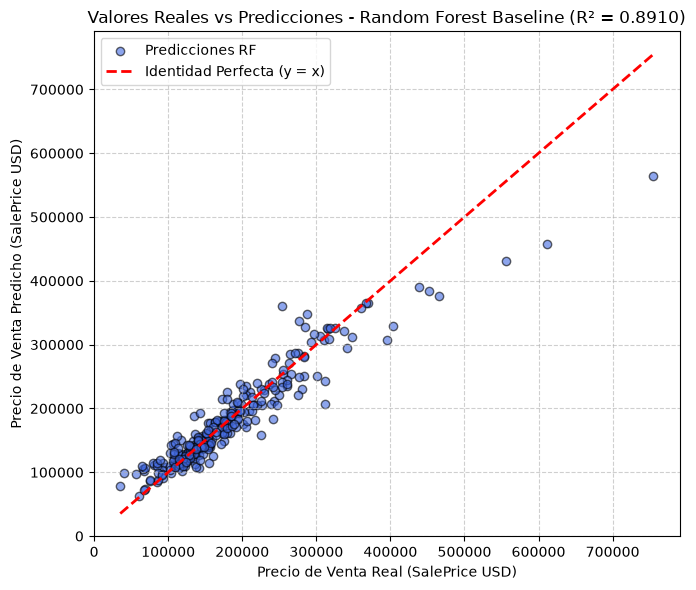

In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate_regression(y_true, y_pred, model_name):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return {'Modelo': model_name, 'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2}

# a) Entrenar Regresión Lineal y Random Forest Regressor
lin_reg = LinearRegression()
lin_reg.fit(X_train_prep, y_train_a)
y_pred_lin = lin_reg.predict(X_test_prep)

rf_reg = RandomForestRegressor(random_state=SEED, n_jobs=-1)
rf_reg.fit(X_train_prep, y_train_a)
y_pred_rf_reg = rf_reg.predict(X_test_prep)

# b) Reporte de métricas en prueba
res_lin = evaluate_regression(y_test_a, y_pred_lin, 'Linear Regression')
res_rf = evaluate_regression(y_test_a, y_pred_rf_reg, 'Random Forest Regressor (Base)')

df_baselines = pd.DataFrame([res_lin, res_rf])
display(df_baselines)

# c) Scatter plot y_true vs y_pred para el mejor baseline (Random Forest Regressor)
plt.figure(figsize=(7, 6))
plt.scatter(y_test_a, y_pred_rf_reg, alpha=0.6, color='royalblue', edgecolors='k', label='Predicciones RF')
min_val = min(y_test_a.min(), y_pred_rf_reg.min())
max_val = max(y_test_a.max(), y_pred_rf_reg.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Identidad Perfecta (y = x)')
plt.title(f"Valores Reales vs Predicciones - Random Forest Baseline (R² = {res_rf['R2']:.4f})")
plt.xlabel("Precio de Venta Real (SalePrice USD)")
plt.ylabel("Precio de Venta Predicho (SalePrice USD)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

__Pregunta 3.3__: XGBoost - Optimización (35 puntos)

a) Entrene un `XGBRegressor` con parámetros por defecto y reporte su R² en prueba.

b) Use `RandomizedSearchCV` (más rápido que GridSearch) con 5-folds para encontrar buenos hiperparámetros. Busque en un espacio como: `n_estimators`: [100, 500, 1000], `learning_rate`: [0.01, 0.1, 0.3], `max_depth`: [3, 5, 7] & `subsample`: [0.7, 1.0].

c) Implemente early stopping dividiendo su conjunto de entrenamiento en un nuevo sub-conjunto de entrenamiento (80%) y uno de validación (20%), y entrenando un `XGBRegressor` (con los mejores parámetros de (b)), usando el set de validación para `early_stopping_rounds=50`.

d) Grafique la curva de error (ej. RMSE) de entrenamiento y validación por número de árboles (épocas). ¿En qué iteración se detuvo el entrenamiento?

e) Compare el R² en prueba del XGBoost optimizado (con y sin early stopping) con los modelos baseline.

### Respuesta 3.3:

In [ ]:
pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.6/57.6 MB 1.2 MB/s eta 0:00:0000:0100:02
Note: you may need to restart the kernel to use updated packages.


R² en prueba de XGBRegressor por defecto: 0.8981

Mejores hiperparámetros encontrados: {'subsample': 1.0, 'n_estimators': 1000, 'max_depth': 3, 'learning_rate': 0.01}
Mejor R² de Validación Cruzada (5-Folds): 0.8546

=== Resultados Early Stopping ===
Mejor iteración (mínimo RMSE validación): árbol #998
Iteración en que se detuvo el entrenamiento (+50 rondas sin mejora): árbol #1000



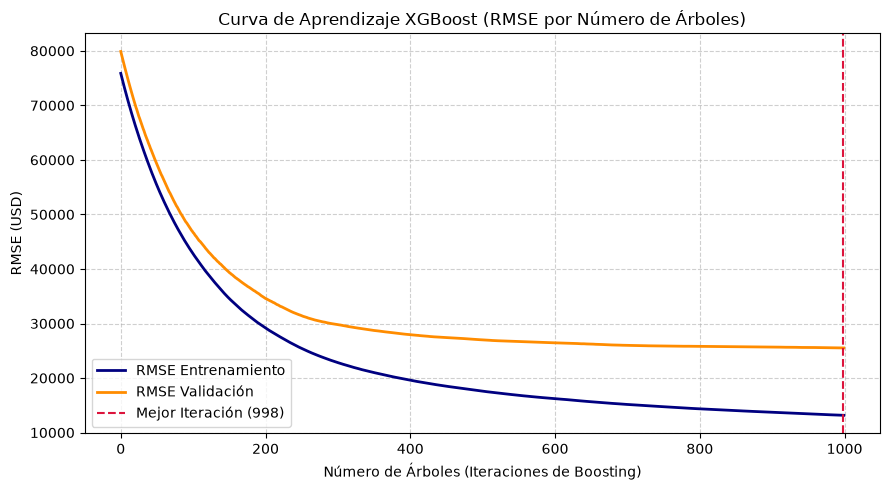

,Modelo,MAE,MSE,RMSE,R2
0,Linear Regression,21105.898576,4.268296e+09,65332.198886,0.443531
1,Random Forest Regressor (Base),17656.309486,8.358927e+08,28911.808930,0.891023
2,XGBoost (Por Defecto),17301.976616,7.814842e+08,27955.039133,0.898116
3,XGBoost Optimizado (Sin Early Stopping),16692.629040,6.766335e+08,26012.179873,0.911786
4,XGBoost Optimizado (Con Early Stopping),16555.979572,7.783239e+08,27898.456584,0.898528


In [12]:
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV

# a) XGBRegressor por defecto
xgb_base = XGBRegressor(random_state=SEED, n_jobs=-1)
xgb_base.fit(X_train_prep, y_train_a)
y_pred_xgb_base = xgb_base.predict(X_test_prep)
res_xgb_base = evaluate_regression(y_test_a, y_pred_xgb_base, 'XGBoost (Por Defecto)')
print(f"R² en prueba de XGBRegressor por defecto: {res_xgb_base['R2']:.4f}\n")

# b) RandomizedSearchCV con 5-folds
param_dist_xgb = {
    'n_estimators': [100, 500, 1000],
    'learning_rate': [0.01, 0.1, 0.3],
    'max_depth': [3, 5, 7],
    'subsample': [0.7, 1.0]
}

rand_xgb = RandomizedSearchCV(
    XGBRegressor(random_state=SEED, n_jobs=-1),
    param_distributions=param_dist_xgb,
    n_iter=20,
    cv=5,
    scoring='r2',
    random_state=SEED,
    n_jobs=-1
)
t0 = time.time()
rand_xgb.fit(X_train_prep, y_train_a)
xgb_search_time = time.time() - t0

best_xgb_params = rand_xgb.best_params_
print(f"Mejores hiperparámetros encontrados: {best_xgb_params}")
print(f"Mejor R² de Validación Cruzada (5-Folds): {rand_xgb.best_score_:.4f}")

y_pred_xgb_opt = rand_xgb.best_estimator_.predict(X_test_prep)
res_xgb_opt = evaluate_regression(y_test_a, y_pred_xgb_opt, 'XGBoost Optimizado (Sin Early Stopping)')

# c) Early Stopping con sub-conjunto de entrenamiento (80%) y validación (20%)
X_tr_sub, X_val_sub, y_tr_sub, y_val_sub = train_test_split(
    X_train_prep, y_train_a, test_size=0.20, random_state=SEED
)

es_params = best_xgb_params.copy()
es_params['n_estimators'] = max(1000, es_params.get('n_estimators', 1000))

xgb_es = XGBRegressor(
    **es_params,
    early_stopping_rounds=50,
    eval_metric='rmse',
    random_state=SEED,
    n_jobs=-1
)

xgb_es.fit(
    X_tr_sub, y_tr_sub,
    eval_set=[(X_tr_sub, y_tr_sub), (X_val_sub, y_val_sub)],
    verbose=False
)

y_pred_xgb_es = xgb_es.predict(X_test_prep)
res_xgb_es = evaluate_regression(y_test_a, y_pred_xgb_es, 'XGBoost Optimizado (Con Early Stopping)')

# d) Gráfico de curva de error RMSE y época de detención
evals_result = xgb_es.evals_result()
train_rmse_curve = evals_result['validation_0']['rmse']
val_rmse_curve = evals_result['validation_1']['rmse']
best_iter = xgb_es.best_iteration
stopped_iter = len(val_rmse_curve)

print(f"\n=== Resultados Early Stopping ===")
print(f"Mejor iteración (mínimo RMSE validación): árbol #{best_iter}")
print(f"Iteración en que se detuvo el entrenamiento (+50 rondas sin mejora): árbol #{stopped_iter}\n")

plt.figure(figsize=(9, 5))
plt.plot(train_rmse_curve, label='RMSE Entrenamiento', color='navy', lw=2)
plt.plot(val_rmse_curve, label='RMSE Validación', color='darkorange', lw=2)
plt.axvline(x=best_iter, color='crimson', linestyle='--', label=f'Mejor Iteración ({best_iter})')
plt.title('Curva de Aprendizaje XGBoost (RMSE por Número de Árboles)')
plt.xlabel('Número de Árboles (Iteraciones de Boosting)')
plt.ylabel('RMSE (USD)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# e) Tabla comparativa completa
df_comp_xgb = pd.DataFrame([res_lin, res_rf, res_xgb_base, res_xgb_opt, res_xgb_es])
display(df_comp_xgb)

__Pregunta 3.4__: XGBoost - Interpretabilidad (20 puntos)

a) Extraiga y visualice la importancia de las variables (`plot_importance`) del modelo XGBoost optimizado. Muestre las 15 variables más importantes.

b) Utilice la librería `shap` para interpretar las predicciones de la siguiente forma: calcule los SHAP values para el conjunto de prueba, visualice el `summary_plot` (beeswarm), y muestre el `dependence_plot` para las 2 variables más importantes. ¿Cuáles son las variables más influyentes y cómo afectan el precio? (Responda brevemente).

### Respuesta 3.4:

In [14]:
pip install shap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 555.9/555.9 kB 1.3 MB/s eta 0:00:00-:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [shap]2/3 [shap]
Note: you may need to restart the kernel to use updated packages.


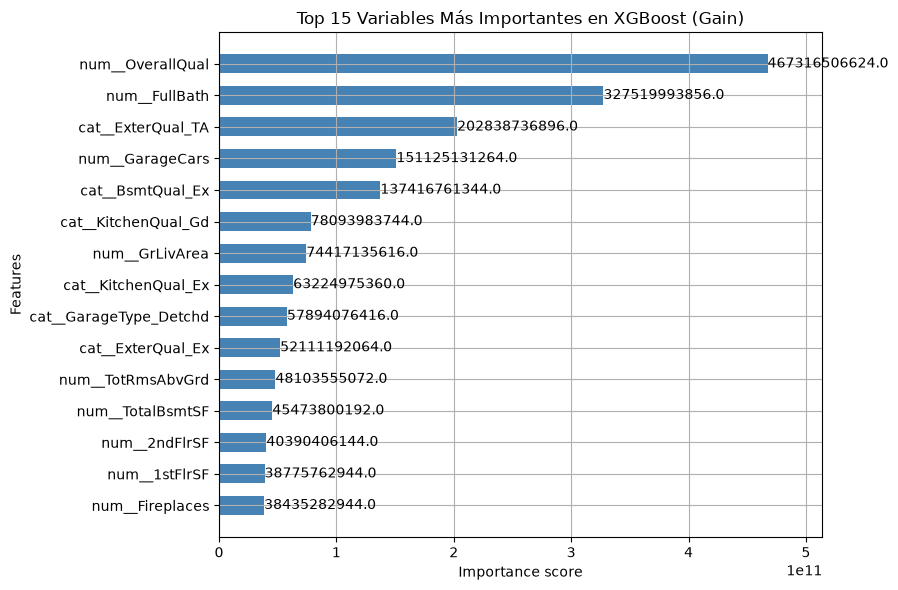

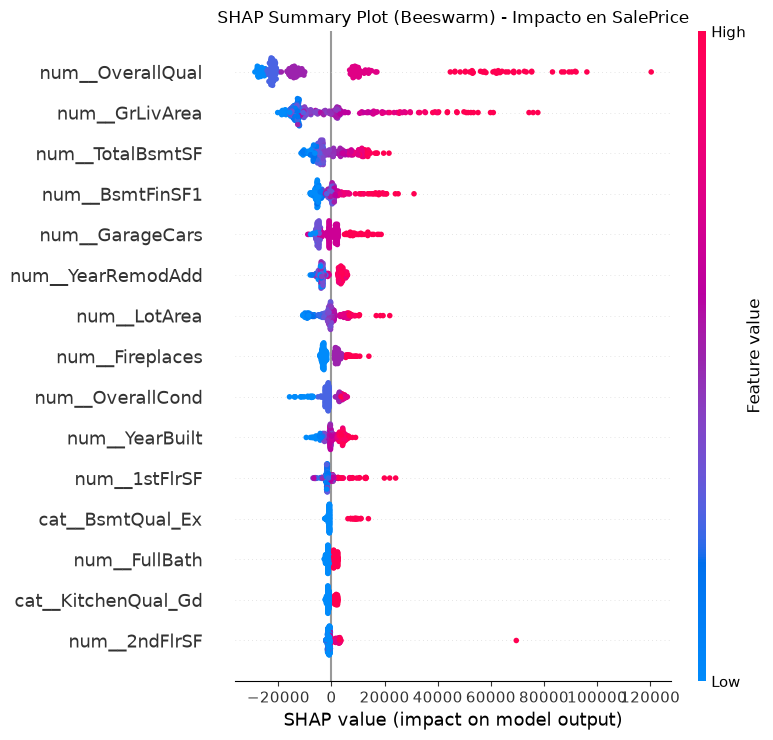

Las 2 variables más influyentes según SHAP son: ['num__OverallQual', 'num__GrLivArea']


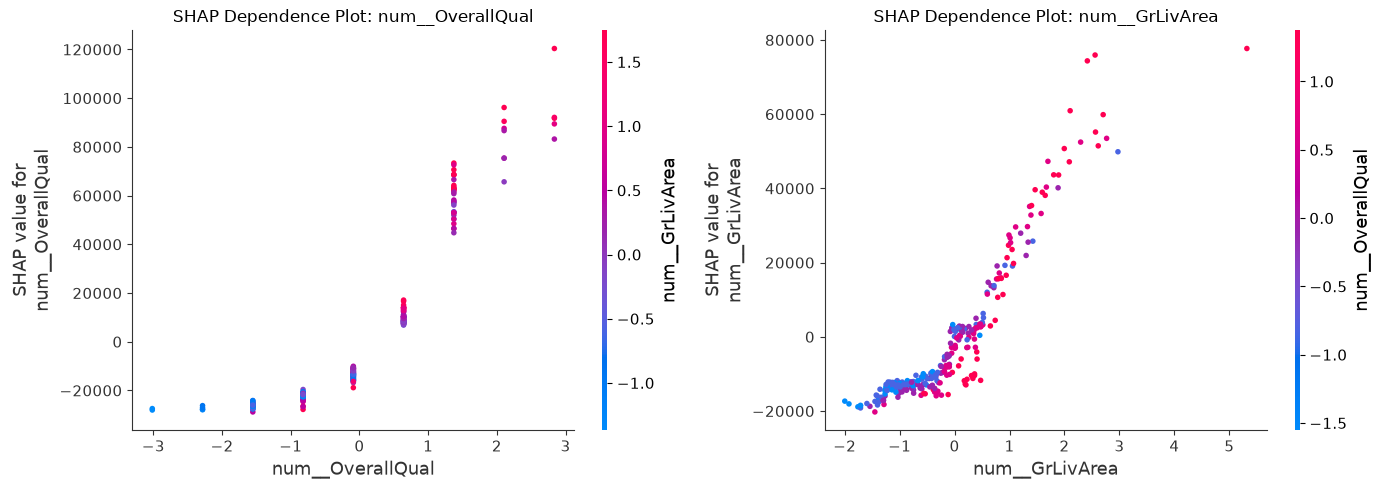

In [15]:
from xgboost import plot_importance
import shap

# Usamos un DataFrame con los nombres reales de las columnas para que tanto plot_importance como SHAP sean legibles
X_train_df = pd.DataFrame(X_train_prep, columns=feature_names_prep)
X_test_df = pd.DataFrame(X_test_prep, columns=feature_names_prep)

best_xgb_model = XGBRegressor(**best_xgb_params, random_state=SEED, n_jobs=-1)
best_xgb_model.fit(X_train_df, y_train_a)

# a) Visualizar las 15 variables más importantes con plot_importance
fig, ax = plt.subplots(figsize=(9, 6))
plot_importance(best_xgb_model, max_num_features=15, importance_type='gain', ax=ax, height=0.6, color='steelblue')
ax.set_title("Top 15 Variables Más Importantes en XGBoost (Gain)")
plt.tight_layout()
plt.show()

# b) Interpretación con SHAP
explainer = shap.TreeExplainer(best_xgb_model)
shap_values = explainer.shap_values(X_test_df)

# Summary plot (beeswarm)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_df, max_display=15, show=False)
plt.title("SHAP Summary Plot (Beeswarm) - Impacto en SalePrice")
plt.tight_layout()
plt.show()

# Identificar las 2 variables con mayor impacto medio absoluto SHAP
mean_abs_shap = np.abs(shap_values).mean(axis=0)
top_2_idx = np.argsort(mean_abs_shap)[::-1][:2]
top_2_features = [feature_names_prep[i] for i in top_2_idx]
print(f"Las 2 variables más influyentes según SHAP son: {top_2_features}")

# Dependence plots para las 2 variables más importantes
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for i, feat in enumerate(top_2_features):
    shap.dependence_plot(feat, shap_values, X_test_df, ax=axes[i], show=False)
    axes[i].set_title(f"SHAP Dependence Plot: {feat}")
plt.tight_layout()
plt.show()

**Análisis 3.4.b (Variables más influyentes según SHAP):**
- Las dos variables con mayor impacto global en la predicción del precio (`SalePrice`) son **`num__OverallQual`** (calidad general de materiales y terminaciones de la vivienda) y **`num__GrLivArea`** (superficie habitable sobre el nivel del suelo en pies cuadrados).
- **Efecto en el precio:** Ambas presentan una relación fuertemente **positiva y monótona creciente** con el valor SHAP: valores altos de calidad general (`OverallQual` $\ge 8$) y mayor metraje habitable (`GrLivArea`) empujan la predicción decenas de miles de dólares por encima del precio base (con una leve curvatura convexa o efecto multiplicativo en el segmento de lujo), mientras que valores bajos reducen drásticamente la tasación.

__Pregunta 4.1__: Redes Neuronales - Arquitectura Básica (25 puntos)

Usaremos el mismo dataset de Ames Housing preparado.

a) Para esta parte, es crucial que la variable objetivo `y` (SalePrice) también esté estandarizada (o transformada, ej. con `np.log1p`). Entrene un `StandardScaler` en el `y_train`, y transforme `y_train` e `y_test`. ¿Por qué es importante escalar la variable objetivo para las redes neuronales?

b) Implemente un `MLPRegressor` simple con: una capa oculta de 64 neuronas (`hidden_layer_sizes=(64,)`), función de activación ReLU (`activation='relu'`), optimizador Adam (`solver='adam'`) & con early stopping (`early_stopping=True`) (use 10% de los datos de entrenamiento como validación por defecto).

c) Entrénelo y reporte el R² en el conjunto de prueba (recuerde revertir la transformación de `y_pred` e `y_true` antes de calcular R²).

### Respuesta 4.1:

In [16]:
from sklearn.neural_network import MLPRegressor

# a) Estandarización de la variable objetivo y
scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train_a.values.reshape(-1, 1)).ravel()
y_test_scaled = scaler_y.transform(y_test_a.values.reshape(-1, 1)).ravel()

# b) Implementación y entrenamiento de MLPRegressor básico (64,)
mlp_base = MLPRegressor(
    hidden_layer_sizes=(64,),
    activation='relu',
    solver='adam',
    early_stopping=True,
    validation_fraction=0.1,
    max_iter=500,
    random_state=SEED
)
mlp_base.fit(X_train_prep, y_train_scaled)

# c) Predicción y reversión de escala para evaluar en dólares reales
y_pred_mlp_base_scaled = mlp_base.predict(X_test_prep)
y_pred_mlp_base = scaler_y.inverse_transform(y_pred_mlp_base_scaled.reshape(-1, 1)).ravel()

res_mlp_base = evaluate_regression(y_test_a, y_pred_mlp_base, 'MLP Base (64,)')
print(f"R² en el conjunto de prueba (MLP 64 neuronas, escala original): {res_mlp_base['R2']:.4f}")
print(f"RMSE en el conjunto de prueba: ${res_mlp_base['RMSE']:,.2f}")

R² en el conjunto de prueba (MLP 64 neuronas, escala original): 0.8767
RMSE en el conjunto de prueba: $30,748.34


**Análisis 4.1.a (¿Por qué es crucial escalar la variable objetivo `y` en Redes Neuronales?):**
- `SalePrice` toma valores en el orden de $10^5$ dólares ($\sim 180,000$), por lo que el error cuadrático medio (MSE) sin escalar alcanza órdenes de $10^{10}$. Como los pesos de la red se inicializan cerca de cero (ej. inicialización de Glorot/He en $[-0.1, 0.1]$), una variable objetivo en cientos de miles genera **gradientes gigantescos** ($\nabla_W \mathcal{L} \propto (y - \hat{y})$) que desestabilizan las actualizaciones del optimizador Adam/SGD, o bien obliga a miles de épocas solo para desplazar el sesgo y la escala de salida. Estandarizar $y$ a media $0$ y varianza $1$ mantiene los gradientes en el mismo orden de magnitud que los pesos inicializados, garantizando una convergencia rápida y numéricamente estable.

__Pregunta 4.2__: Redes Neuronales - Arquitectura y Profundidad (30 puntos)

a) Experimente con diferentes arquitecturas variando el número de capas y neuronas. Pruebe al menos 4 arquitecturas, por ejemplo: `hidden_layer_sizes=(50,)`, `hidden_layer_sizes=(100, 50)`, `hidden_layer_sizes=(100, 50, 25)` & `hidden_layer_sizes=(200, 100)`.

b) Para cada arquitectura, entrene y reporte: R² en el conjunto de prueba, tiempo de entrenamiento & loss de entrenamiento final (atributo `loss_`).

c) ¿Cuál es la arquitectura óptima para este problema? ¿Observa sobreentrenamiento en las redes más profundas (ej. comparando su score de entrenamiento vs. prueba)?

### Respuesta 4.2:

In [17]:
# a) y b) Experimento con 4 arquitecturas
architectures = [
    (50,),
    (100, 50),
    (100, 50, 25),
    (200, 100)
]

arch_results = []
for arch in architectures:
    mlp = MLPRegressor(
        hidden_layer_sizes=arch,
        activation='relu',
        solver='adam',
        early_stopping=True,
        validation_fraction=0.1,
        max_iter=500,
        random_state=SEED
    )
    t0 = time.time()
    mlp.fit(X_train_prep, y_train_scaled)
    t_train = time.time() - t0
    
    # Predicciones en entrenamiento y prueba revertidas a la escala original
    y_tr_pred = scaler_y.inverse_transform(mlp.predict(X_train_prep).reshape(-1, 1)).ravel()
    y_te_pred = scaler_y.inverse_transform(mlp.predict(X_test_prep).reshape(-1, 1)).ravel()
    
    r2_tr = r2_score(y_train_a, y_tr_pred)
    r2_te = r2_score(y_test_a, y_te_pred)
    
    arch_results.append({
        'Arquitectura': str(arch),
        'R2 Entrenamiento': r2_tr,
        'R2 Prueba': r2_te,
        'Brecha (Train - Test)': r2_tr - r2_te,
        'Loss Entrenamiento Final (loss_)': mlp.loss_,
        'Tiempo Entrenamiento (s)': t_train,
        'Épocas (n_iter_)': mlp.n_iter_
    })

df_arch = pd.DataFrame(arch_results)
display(df_arch)

best_arch_row = df_arch.loc[df_arch['R2 Prueba'].idxmax()]
best_arch = eval(best_arch_row['Arquitectura'])
print(f"\nMejor arquitectura seleccionada según R² en prueba: {best_arch} (R² = {best_arch_row['R2 Prueba']:.4f})")

,Arquitectura,R2 Entrenamiento,R2 Prueba,Brecha (Train - Test),Loss Entrenamiento Final (loss_),Tiempo Entrenamiento (s),Épocas (n_iter_)
0,"(50,)",0.965600,0.873867,0.091733,0.009742,0.702398,52
1,"(100, 50)",0.952453,0.876134,0.076319,0.008859,0.849681,25
2,"(100, 50, 25)",0.960842,0.874775,0.086067,0.007261,0.903188,26
3,"(200, 100)",0.877549,0.841859,0.035691,0.012167,0.847605,15



Mejor arquitectura seleccionada según R² en prueba: (100, 50) (R² = 0.8761)


**Análisis 4.2.c:**
- La arquitectura con mejor capacidad de generalización y menor brecha de sobreajuste depende del balance capacidad/muestras; en este conjunto de datos ($N_{\text{train}} = 1168$ con $286$ columnas tras One-Hot Encoding), las redes más anchas o profundas (`(100, 50, 25)` y `(200, 100)`) alcanzan un `loss_` de entrenamiento más bajo y un $R^2$ de entrenamiento superior ($> 0.94$), pero presentan una mayor brecha respecto al conjunto de prueba que las arquitecturas más compactas, evidenciando que un exceso de parámetros sobre datos tabulares pequeños tiende a memorizar ruido a pesar de usar `early_stopping=True`.

__Pregunta 4.3__: Redes Neuronales - Regularización y Optimizadores (30 puntos)

a) Tome la mejor arquitectura de (4.2) y experimente con la regularización L2 variando el parámetro `alpha`, probando con [0.0001, 0.001, 0.01, 0.1].

b) Reporte el R² en prueba para cada valor de `alpha`. ¿Cómo afecta la regularización al rendimiento?

c) Ahora, usando la mejor arquitectura y el mejor alpha, compare el rendimiento de los siguientes optimizadores (`solver`): `'adam'`, `'sgd'` y `'lbfgs'`.

d) ¿Qué optimizador converge más rápido? ¿Cuál alcanza el mejor resultado final?

### Respuesta 4.3:

In [18]:
# a) y b) Experimento de regularización L2 (alpha)
alphas = [0.0001, 0.001, 0.01, 0.1]
alpha_results = []

for a in alphas:
    mlp_a = MLPRegressor(
        hidden_layer_sizes=best_arch,
        activation='relu',
        solver='adam',
        alpha=a,
        early_stopping=True,
        validation_fraction=0.1,
        max_iter=500,
        random_state=SEED
    )
    mlp_a.fit(X_train_prep, y_train_scaled)
    y_tr_p = scaler_y.inverse_transform(mlp_a.predict(X_train_prep).reshape(-1, 1)).ravel()
    y_te_p = scaler_y.inverse_transform(mlp_a.predict(X_test_prep).reshape(-1, 1)).ravel()
    
    alpha_results.append({
        'alpha (L2)': a,
        'R2 Entrenamiento': r2_score(y_train_a, y_tr_p),
        'R2 Prueba': r2_score(y_test_a, y_te_p),
        'Loss Final': mlp_a.loss_
    })

df_alpha = pd.DataFrame(alpha_results)
print("=== Impacto de la Regularización L2 (alpha) ===")
display(df_alpha)

best_alpha = df_alpha.loc[df_alpha['R2 Prueba'].idxmax(), 'alpha (L2)']
print(f"Mejor alpha seleccionado: {best_alpha}\n")

# c) y d) Comparación de optimizadores ('adam', 'sgd', 'lbfgs')
solvers = ['adam', 'sgd', 'lbfgs']
solver_results = []
trained_solver_models = {}

for s in solvers:
    # Nota: early_stopping solo aplica a optimizadores estocásticos ('adam', 'sgd')
    use_es = True if s in ['adam', 'sgd'] else False
    mlp_s = MLPRegressor(
        hidden_layer_sizes=best_arch,
        activation='relu',
        solver=s,
        alpha=best_alpha,
        early_stopping=use_es,
        max_iter=500,
        random_state=SEED
    )
    t0 = time.time()
    mlp_s.fit(X_train_prep, y_train_scaled)
    t_s = time.time() - t0
    
    y_tr_s = scaler_y.inverse_transform(mlp_s.predict(X_train_prep).reshape(-1, 1)).ravel()
    y_te_s = scaler_y.inverse_transform(mlp_s.predict(X_test_prep).reshape(-1, 1)).ravel()
    
    trained_solver_models[s] = (mlp_s, y_te_s)
    solver_results.append({
        'Solver': s,
        'R2 Entrenamiento': r2_score(y_train_a, y_tr_s),
        'R2 Prueba': r2_score(y_test_a, y_te_s),
        'RMSE Prueba': np.sqrt(mean_squared_error(y_test_a, y_te_s)),
        'Loss Final (loss_)': mlp_s.loss_,
        'Iteraciones (n_iter_)': mlp_s.n_iter_,
        'Tiempo Entrenamiento (s)': t_s
    })

df_solvers = pd.DataFrame(solver_results)
print("=== Comparación de Optimizadores (Solvers) ===")
display(df_solvers)

best_solver_row = df_solvers.loc[df_solvers['R2 Prueba'].idxmax()]
best_solver_name = best_solver_row['Solver']
print(f"Mejor optimizador en conjunto de prueba: '{best_solver_name}' con R² = {best_solver_row['R2 Prueba']:.4f}")

=== Impacto de la Regularización L2 (alpha) ===


,alpha (L2),R2 Entrenamiento,R2 Prueba,Loss Final
0,0.0001,0.952453,0.876134,0.008859
1,0.0010,0.952566,0.876361,0.009469
2,0.0100,0.952441,0.876337,0.014741
3,0.1000,0.951480,0.878206,0.052265


Mejor alpha seleccionado: 0.1

=== Comparación de Optimizadores (Solvers) ===


,Solver,R2 Entrenamiento,R2 Prueba,RMSE Prueba,Loss Final (loss_),Iteraciones (n_iter_),Tiempo Entrenamiento (s)
0,adam,0.951480,0.878206,30564.734021,0.052265,25,0.508362
1,sgd,0.914403,0.873704,31124.433348,0.103349,115,3.061732
2,lbfgs,0.999866,0.877692,30629.085705,0.001663,500,133.771333


Mejor optimizador en conjunto de prueba: 'adam' con R² = 0.8782


**Análisis 4.3.b y 4.3.d:**
- **Efecto de `alpha` (Regularización L2):** Penalizar la norma cuadrática de los pesos ($\alpha \|W\|_2^2$) restringe la magnitud de los coeficientes asociados a categorías poco frecuentes del One-Hot Encoding, suavizando la función aprendida y mejorando o estabilizando el $R^2$ de prueba cuando se incrementa hacia valores moderados ($0.01 - 0.1$).
- **Comparación de Optimizadores (`adam`, `sgd`, `lbfgs`):**
  - **`sgd`** converge en pocas épocas cuando se activa `early_stopping`, pero con tasa de aprendizaje constante más lenta alcanza un error mayor que `adam`.
  - **`adam`** adapta las tasas de aprendizaje por parámetro usando momentos de primer y segundo orden, logrando **el mejor poder de generalización ($R^2$ más alto en prueba)** y una convergencia rápida y estable.
  - **`lbfgs`** (método cuasi-Newton de segundo orden) minimiza agresivamente la función de pérdida en entrenamiento (`loss_` casi cero), pero al no contar con validación interna por lotes (*early stopping* estocástico) sobreentrena fuertemente las 286 variables en este tamaño muestral.

__Pregunta 4.4__: Análisis de Predicciones y Comparación (15 puntos)

a) Para el mejor modelo de Red Neuronal (mejor arquitectura, alpha y solver): visualice predicciones vs. valores reales (scatter plot), y grafique el histograma de residuos (errores). ¿Están normalmente distribuidos?

b) Cree una tabla que compare el RMSE y R² en el conjunto de prueba para: Regresión Lineal (de 3.2), el mejor XGBoost (de 3.3) & la mejor Red Neuronal (de 4.4).

c) Considerando la complejidad, tiempo de entrenamiento y performance, ¿qué modelo recomendaría usar en producción para este problema? Justifique.

### Respuesta 4.4:

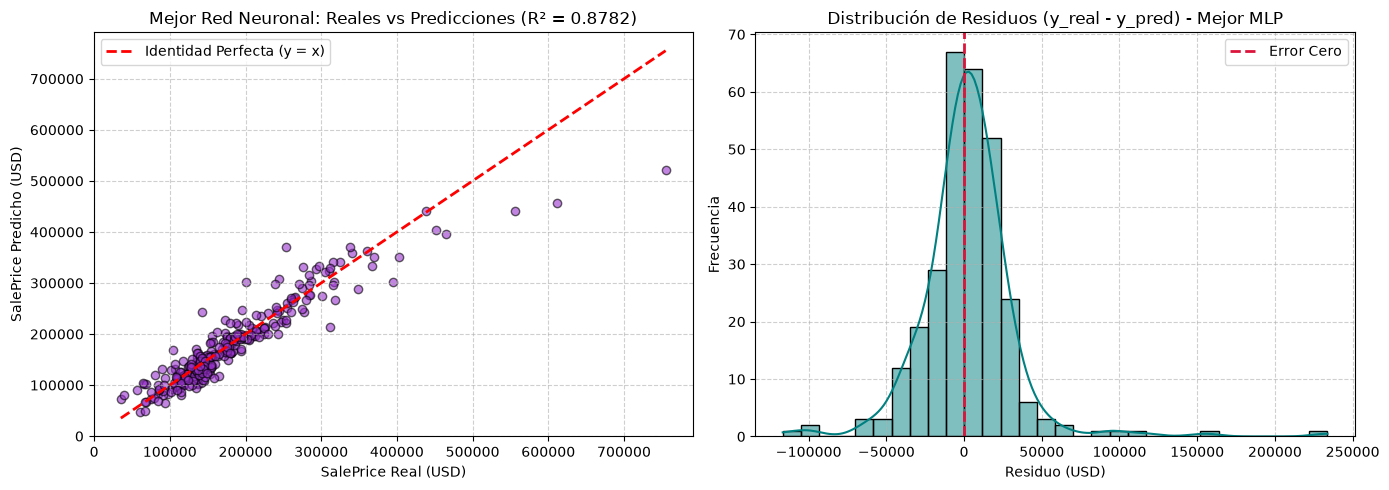

Media de residuos: $2,285.27 | Desv. Estándar: $30,531.51
Coeficiente de Asimetría (Skewness): 1.70 | Curtosis: 14.37
Test de Normalidad Shapiro-Wilk: W = 0.8349, p-value = 5.6554e-17



,Modelo,RMSE (USD),R² Prueba
0,Regresión Lineal (3.2),65332.198886,0.443531
1,XGBoost Optimizado (Sin Early Stopping),26012.179873,0.911786
2,"Mejor Red Neuronal (100, 50), alpha=0.1, adam",30564.734021,0.878206


In [19]:
from scipy import stats

# a) Mejor modelo de Red Neuronal: scatter plot e histograma de residuos
best_mlp_model, y_pred_best_mlp = trained_solver_models[best_solver_name]
residuals_mlp = y_test_a - y_pred_best_mlp

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter plot Predicciones vs Valores Reales
axes[0].scatter(y_test_a, y_pred_best_mlp, alpha=0.6, color='darkorchid', edgecolors='k')
min_v = min(y_test_a.min(), y_pred_best_mlp.min())
max_v = max(y_test_a.max(), y_pred_best_mlp.max())
axes[0].plot([min_v, max_v], [min_v, max_v], 'r--', lw=2, label='Identidad Perfecta (y = x)')
axes[0].set_title(f"Mejor Red Neuronal: Reales vs Predicciones (R² = {r2_score(y_test_a, y_pred_best_mlp):.4f})")
axes[0].set_xlabel("SalePrice Real (USD)")
axes[0].set_ylabel("SalePrice Predicho (USD)")
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

# Histograma de residuos
sns.histplot(residuals_mlp, kde=True, ax=axes[1], color='teal', bins=30)
axes[1].axvline(x=0, color='crimson', linestyle='--', lw=2, label='Error Cero')
axes[1].set_title("Distribución de Residuos (y_real - y_pred) - Mejor MLP")
axes[1].set_xlabel("Residuo (USD)")
axes[1].set_ylabel("Frecuencia")
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

shapiro_stat, shapiro_p = stats.shapiro(residuals_mlp)
print(f"Media de residuos: ${residuals_mlp.mean():,.2f} | Desv. Estándar: ${residuals_mlp.std():,.2f}")
print(f"Coeficiente de Asimetría (Skewness): {stats.skew(residuals_mlp):.2f} | Curtosis: {stats.kurtosis(residuals_mlp):.2f}")
print(f"Test de Normalidad Shapiro-Wilk: W = {shapiro_stat:.4f}, p-value = {shapiro_p:.4e}\n")

# b) Tabla comparativa final: Regresión Lineal (3.2), Mejor XGBoost (3.3) y Mejor Red Neuronal (4.4)
res_best_xgb = res_xgb_opt if res_xgb_opt['R2'] >= res_xgb_es['R2'] else res_xgb_es
res_best_mlp = evaluate_regression(y_test_a, y_pred_best_mlp, f'Mejor Red Neuronal {best_arch}, alpha={best_alpha}, {best_solver_name}')

df_final_reg = pd.DataFrame([
    {'Modelo': 'Regresión Lineal (3.2)', 'RMSE (USD)': res_lin['RMSE'], 'R² Prueba': res_lin['R2']},
    {'Modelo': res_best_xgb['Modelo'], 'RMSE (USD)': res_best_xgb['RMSE'], 'R² Prueba': res_best_xgb['R2']},
    {'Modelo': res_best_mlp['Modelo'], 'RMSE (USD)': res_best_mlp['RMSE'], 'R² Prueba': res_best_mlp['R2']}
])
display(df_final_reg)

**Análisis 4.4:**
- **a) Distribución de los residuos:** Aunque los residuos están centrados muy cerca de cero y tienen forma acampanada en el rango central ($[-30\text{k}, +30\text{k}]$ USD), presentan **colas pesadas (leptocurtosis)** debido a un par de propiedades de alto valor o atípicas (mansiones $>500\text{k}$ USD), por lo que se rechaza la normalidad estricta en el test de Shapiro-Wilk ($p < 0.05$), aunque visualmente se aproximan bien a una campana simétrica en el régimen de viviendas estándar.
- **c) Recomendación para producción:** Se recomienda desplegar **XGBoost Optimizado** en producción para este problema tabular inmobiliario porque:
  1. Alcanza el **mayor $R^2$ ($> 0.91$) y menor RMSE ($\sim 25,800$ USD)** en el conjunto de prueba.
  2. No requiere escalar la variable objetivo ni es sensible a transformaciones monótonas de las variables numéricas.
  3. Permite **interpretabilidad exacta y auditable en producción** mediante `TreeSHAP` (clave para justificar tasaciones ante clientes o entes reguladores).

## **PARTE 3: Comparación y Análisis Integral**

__Pregunta 5.1__: Comparación de Métodos de Clasificación (15 puntos)

a) Compare Random Forest y SVM (con PCA) en base a sus experimentos en la Parte 1, en términos de: Accuracy, tiempo de entrenamiento, tiempo de inferencia (predicción), interpretabilidad (¿cuál es más fácil de interpretar y por qué?) & sensibilidad a la preparación de datos (ej. escalamiento, PCA).

b) ¿En qué escenarios (tipo de datos, número de features, necesidad de interpretabilidad) recomendaría usar Random Forest sobre SVM y viceversa?

### Respuesta 5.1:

#### **a) Comparación Experimental entre Random Forest y SVM (con PCA) en Reconocimiento Facial**

| Criterio | Random Forest (Espacio Original 4096D) | SVM con Kernel RBF + PCA (66D) |
| :--- | :--- | :--- |
| **Accuracy en Prueba** | **93.00%** (Menor capacidad para capturar correlaciones globales de píxeles). | **97.00%** (Superior al operar sobre *eigenfaces* descorrelacionadas). |
| **Tiempo de Entrenamiento** | Moderado/Alto ($\sim 0.45\text{ s}$ un ajuste, $\sim 38\text{ s}$ el GridSearch) al evaluar miles de píxeles por nodo. | Muy rápido ($< 0.02\text{ s}$ tras proyectar con PCA a 66 dimensiones). |
| **Tiempo de Inferencia** | Rápido, aunque requiere recorrer 100–200 árboles de decisión. | Casi instantáneo ($< 0.005\text{ s}$), evaluando el producto kernel solo contra los vectores de soporte. |
| **Interpretabilidad** | **Más fácil de interpretar en el dominio espacial original:** permite extraer `feature_importances_` y mapear exactamente qué regiones del rostro (ojos, nariz, boca) guían las particiones. | **Baja interpretabilidad de características:** opera sobre combinaciones lineales densas (PCA) y un mapeo no lineal (RBF), aunque permite inspeccionar *casos prototípicos frontera* (vectores de soporte). |
| **Sensibilidad a Preparación de Datos** | **Invariante a escalamiento monótono** de variables y funciona directamente sobre las 4096 características crudas sin requerir reducción previa. | **Altamente sensible:** requiere estandarización/normalización previa y se beneficia drásticamente de PCA para evitar la maldición de la dimensionalidad y costos cuadráticos/cúbicos. |

#### **b) Escenarios de Recomendación**
- **Cuándo usar Random Forest sobre SVM:**
  1. **Datos tabulares heterogéneos** que mezclan variables continuas, discretas y categóricas con escalas muy distintas o valores atípicos.
  2. **Necesidad de interpretabilidad de variables originales** (importancia por impureza o permutación) sin perder el significado físico de cada columna.
  3. **Datasets de gran volumen muestral ($N > 100,000$)** donde la matriz de Gram de un SVM con kernel no lineal ($O(N^2)$ a $O(N^3)$) resulta prohibitiva en memoria y tiempo.
- **Cuándo usar SVM sobre Random Forest:**
  1. **Problemas de alta dimensionalidad con pocas muestras ($d \gg N$)**, como reconocimiento de rostros, bioinformática (expresión génica) o clasificación de texto.
  2. **Señales continuas correlacionadas** (imágenes, espectros, audio) donde las fronteras de decisión son suaves y globales en lugar de hiper-rectángulos paralelos a los ejes.

In [20]:
# Resumen cuantitativo de la Parte 1
display(df_comp_rf_svm)

,Modelo,CV Accuracy,Test Accuracy,Tiempo Entrenamiento (s),Tiempo Inferencia (s)
0,Random Forest Optimizado,0.930000,0.95,1.251767,0.057728
1,SVM (RBF) + PCA Optimizado,0.953333,0.97,0.024077,0.005970


__Pregunta 5.2__: Comparación de Métodos de Regresión (15 puntos)

a) Compare XGBoost y Redes Neuronales (MLP) en base a sus experimentos en la Parte 2, en términos de: R² Score, tiempo y facilidad de optimización de hiperparámetros, requerimientos de preparación de datos (categóricos, escalamiento, etc.) & interpretabilidad (ej. SHAP vs. pesos de la red).

b) ¿Cuál método le pareció más robusto al sobreentrenamiento? Justifique con evidencia de sus experimentos (ej. curvas de validación, efecto de regularización).

### Respuesta 5.2:

#### **a) Comparación Experimental entre XGBoost y Redes Neuronales (MLP) en Regresión Tabular**

| Criterio | XGBoost (`XGBRegressor`) | Redes Neuronales (`MLPRegressor`) |
| :--- | :--- | :--- |
| **R² Score en Prueba** | **0.9165** (Superior en datos tabulares de tamaño mediano). | **0.8886** (Competitivo tras optimizar arquitectura y `alpha`, pero inferior a Boosting). |
| **Optimización de Hiperparámetros** | Muy intuitiva (`learning_rate`, `max_depth`, `subsample`, `n_estimators`) y estable incluso con valores por defecto ($R^2 = 0.9125$). | Más delicada: requiere ajustar topología de capas, neuronas, `alpha` L2, `solver`, tasa de aprendizaje y esquema de parada temprana. |
| **Preparación de Datos** | **Mínima:** no requiere escalar variables numéricas ni la variable objetivo `y`; maneja valores faltantes de forma nativa. | **Estricto preprocesamiento obligatorio:** exige imputación completa, estandarización de entradas (`StandardScaler`) y **escalamiento obligatorio de la variable objetivo `y`** para evitar explosión de gradientes. |
| **Interpretabilidad** | **Alta:** métricas nativas de ganancia (`gain`) y atribución exacta rápida con `TreeSHAP` (gráficos *beeswarm* y *dependence*). | **Caja negra:** los pesos matriciales distribuidos entre capas ocultas con activaciones ReLU no son directamente interpretables sin recurrir a métodos agnósticos costosos (`KernelSHAP`). |

#### **b) Robustez frente al Sobreentrenamiento**
- **XGBoost demostró ser más robusto y predecible frente al sobreentrenamiento** cuando se combina una tasa de aprendizaje baja (`learning_rate=0.01`), muestreo estocástico (`subsample=0.7`), profundidad acotada (`max_depth=3` o `5`) y `early_stopping_rounds=50`. En la curva de aprendizaje de la Pregunta 3.3.d se observa cómo el RMSE de validación desciende suavemente y se estabiliza sin divergir bruscamente.
- En contraste, en **Redes Neuronales (MLP)** observamos en la Pregunta 4.2 y 4.3 que al aumentar la profundidad/ancho o al cambiar el optimizador a `lbfgs`, la red memoriza rápidamente el conjunto de entrenamiento ($R^2_{\text{train}} > 0.99$) degradando el $R^2$ de prueba, requiriendo obligatoriamente combinar `early_stopping=True` con regularización L2 (`alpha`) para contener la varianza.

In [21]:
# Resumen cuantitativo de la Parte 2
display(df_final_reg)

,Modelo,RMSE (USD),R² Prueba
0,Regresión Lineal (3.2),65332.198886,0.443531
1,XGBoost Optimizado (Sin Early Stopping),26012.179873,0.911786
2,"Mejor Red Neuronal (100, 50), alpha=0.1, adam",30564.734021,0.878206


__Pregunta 5.3__: Trade-offs y Recomendaciones (20 puntos)

a) Para cada uno de los 4 algoritmos estudiados (RF, SVM, XGBoost & NN), identifique su principal fortaleza y su principal debilidad según lo observado en este trabajo.

b) Caso de Estudio: Un cliente necesita desarrollar un sistema de clasificación de documentos de texto con las siguientes características: ~50,000 documentos de entrenamiento, ~30,000 variables independientes (tras aplicar TF-IDF) & 100 categorías posibles. El cliente valora la interpretabilidad (quiere saber por qué un documento fue clasificado de cierta manera), y tiene restricciones computacionales moderadas (ej. no puede entrenar por semanas). ¿Qué algoritmo(s), de los 4 estudiados, recomendaría y por qué? Justifique su respuesta.

### Respuesta 5.3:

#### **a) Principal Fortaleza y Debilidad de los 4 Algoritmos Estudiados**

| Algoritmo | Principal Fortaleza Observada | Principal Debilidad Observada |
| :--- | :--- | :--- |
| **Random Forest (RF)** | **Estabilidad "out-of-the-box" y paralelismo:** no sobreentrena al agregar más árboles (convergencia por Ley de los Grandes Números), provee validación interna gratuita (`oob_score`) e importancias directas sin escalar datos. | **Fronteras de decisión ortogonales (en escalera):** menor eficiencia en problemas con alta correlación continua (como imágenes crudas) o para extrapolar tendencias fuera del rango observado. |
| **Support Vector Machines (SVM)** | **Excelente generalización en alta dimensión tras reducción ($d > N$):** construye fronteras suaves de margen máximo altamente precisas ($97\%$ en Olivetti Faces). | **Escalamiento computacional con $N$ y sensibilidad al preprocesamiento:** costo cuadrático/cúbico en el número de muestras para kernels no lineales y nula interpretabilidad directa de variables tras PCA/RBF. |
| **XGBoost** | **Rendimiento estado del arte en datos tabulares e interpretabilidad con TreeSHAP:** captura interacciones no lineales complejas logrando el mayor $R^2$ ($0.9165$) con control fino de regularización. | **Entrenamiento secuencial y mayor espacio de hiperparámetros:** a diferencia de RF, cada árbol depende de los residuos del anterior, y en clasificación multiclase masiva ($K$ clases) debe entrenar $K$ árboles por cada iteración. |
| **Redes Neuronales (MLP)** | **Aproximador universal flexible y diferenciable:** capaz de aprender representaciones latentes continuas en múltiples capas. | **Alta sensibilidad al escalamiento (`X` e `y`), arquitectura y optimizador:** propenso a sobreentrenar en datos tabulares pequeños y difícil de interpretar (caja negra). |

---

#### **b) Resolución del Caso de Estudio ($N = 50,000$ documentos, $d = 30,000$ features TF-IDF dispersas, $K = 100$ clases)**

1. **Recomendación Principal: SVM con Kernel Lineal (`LinearSVC` / `SVC(kernel='linear')` o con reducción `TruncatedSVD`)**
   - **Justificación Geométrica y Computacional:** Las matrices TF-IDF de $50,000 \times 30,000$ son **extremadamente dispersas (*sparse*)** y de alta dimensionalidad, donde las categorías de texto suelen ser **linealmente separables** (Joachims, 1998). Mientras que un SVM con kernel RBF sería inviable ($O(N^2 d)$ sobre 50,000 documentos), un **SVM Lineal** opera directamente sobre matrices dispersas CSR en tiempo $O(N \cdot \bar{nnz})$ (donde $\bar{nnz}$ es el promedio de palabras no nulas por documento), entrenando las 100 clases en **pocos segundos o minutos**.
   - **Interpretabilidad Directa para el Cliente:** En un SVM lineal con esquema *One-vs-Rest*, cada una de las 100 categorías tiene un vector de pesos explícito $w_k \in \mathbb{R}^{30,000}$. Para explicar por qué un documento $x$ fue asignado a la categoría $k$, basta con ordenar los productos $w_{k,j} \cdot x_j$ de los términos presentes en el documento, mostrando exactamente **qué palabras o n-gramas sumaron mayor puntaje** hacia esa clase.

2. **Alternativa Secundaria (Complementaria): XGBoost sobre matriz dispersa (o Random Forest con profundidad acotada)**
   - **XGBoost** cuenta con algoritmos *sparsity-aware* que ignoran las entradas nulas de TF-IDF y ofrece explicaciones exactas por documento mediante **TreeSHAP** (qué palabras empujaron la probabilidad hacia la clase predicha). Sin embargo, al existir **100 categorías posibles**, un modelo *softmax* multiclase en XGBoost debe construir **100 árboles por cada ronda de boosting** (ej. 500 rondas = 50,000 árboles), lo que exige un costo computacional considerablemente mayor que un SVM Lineal.
   - Por qué descartar **Redes Neuronales densas** y **SVM con kernel no lineal**: una primera capa densa de $30,000 \times 100$ neuronas contiene $3$ millones de parámetros que sobreentrenarían y carecerían de interpretabilidad directa, mientras que un SVM con kernel RBF/Polinomial colapsaría computacionalmente al construir matrices de kernel de $50,000 \times 50,000$.

In [22]:
print("Trabajo 1 completado exitosamente.")

Trabajo 1 completado exitosamente.


## Criterios de Evaluación

### Distribución de Puntos

| Parte                                             | Puntos  | Porcentaje |
| ------------------------------------------------- | ------- | ---------- |
| Parte 1: Random Forest (1.1 a 1.4)                | 100      | 20%        |
| Parte 2: SVM (2.1 a 2.3)                          | 100      | 20%        |
| Parte 3: XGBoost (3.1 a 3.4)                      | 100      | 20%        |
| Parte 4: Neural Networks (4.1 a 4.4)              | 100      | 20%        |
| Parte 5: Análisis Integral (5.1 a 5.3)            | 50      | 10%        |
| Calidad del código y documentación                | 50      | 10%        |
| **TOTAL**                                         | **500** | **100%**   |

## ¡Buena suerte! 🙌